## import liabraries

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

## Load dataset

In [3]:
df = pd.read_csv(
    r"C:\Users\User\Downloads\spamhamdata.csv",
    sep="\t",
    header=None,
    names=["label", "message"]
)

df.head()

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [5]:
print(df.shape)

(5572, 2)
label      0
message    0
dtype: int64
403


In [6]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   label    5572 non-null   str  
 1   message  5572 non-null   str  
dtypes: str(2)
memory usage: 542.9 KB
None


In [7]:
print(df.isnull().sum())

label      0
message    0
dtype: int64


In [8]:
print(df.duplicated().sum())

403


In [11]:
df = df.dropna()  ## Remove missing values

In [12]:
df = df.drop_duplicates() ## remove duplicate rows

In [13]:
df.shape

(5169, 2)

In [15]:
X = df["message"]

y = df["label"]

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [18]:
cv = CountVectorizer()

X_train = cv.fit_transform(X_train)

X_test = cv.transform(X_test)

In [19]:
## Train the Naive Bayes model
nb = MultinomialNB()

nb.fit(X_train, y_train)

y_pred = nb.predict(X_test)

In [20]:
## Evaluate the original model
print("Accuracy:", accuracy_score(y_test, y_pred))

print("Precision:", precision_score(y_test, y_pred, pos_label="spam"))

print("Recall:", recall_score(y_test, y_pred, pos_label="spam"))

print("F1 Score:", f1_score(y_test, y_pred, pos_label="spam"))

Accuracy: 0.9816247582205029
Precision: 0.9590163934426229
Recall: 0.8931297709923665
F1 Score: 0.924901185770751


In [21]:
## Apply hyperparameter tuning manually
alpha_values = [0.001, 0.01, 0.1, 0.5, 1, 2, 5, 10]

In [22]:
accuracy_values = []

In [23]:
for alpha in alpha_values:

    model = MultinomialNB(alpha=alpha)

    model.fit(X_train, y_train)

    y_pred_tuned = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred_tuned)

    accuracy_values.append(accuracy)

    print("Alpha:", alpha)

    print("Accuracy:", accuracy)

    print("----------------------")

Alpha: 0.001
Accuracy: 0.9777562862669246
----------------------
Alpha: 0.01
Accuracy: 0.9787234042553191
----------------------
Alpha: 0.1
Accuracy: 0.9816247582205029
----------------------
Alpha: 0.5
Accuracy: 0.9864603481624759
----------------------
Alpha: 1
Accuracy: 0.9816247582205029
----------------------
Alpha: 2
Accuracy: 0.9796905222437138
----------------------
Alpha: 5
Accuracy: 0.9671179883945842
----------------------
Alpha: 10
Accuracy: 0.9535783365570599
----------------------


In [24]:
## Find the best alpha value
best_index = np.argmax(accuracy_values)

best_alpha = alpha_values[best_index]

best_accuracy = accuracy_values[best_index]

print("Best Alpha:", best_alpha)

print("Best Accuracy:", best_accuracy)

Best Alpha: 0.5
Best Accuracy: 0.9864603481624759


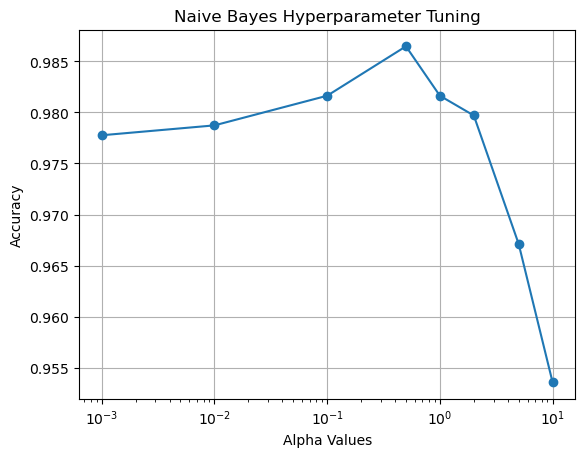

In [25]:
## Visualize hyperparameter tuning
plt.plot(alpha_values, accuracy_values, marker="o")

plt.xlabel("Alpha Values")

plt.ylabel("Accuracy")

plt.title("Naive Bayes Hyperparameter Tuning")

plt.xscale("log")

plt.grid()

plt.show()

In [26]:
## Train the final model using the best alpha
best_nb = MultinomialNB(alpha=best_alpha)
best_nb.fit(X_train, y_train)
y_pred_best = best_nb.predict(X_test)

In [27]:
## Evaluate the tuned model
print("Accuracy:", accuracy_score(y_test, y_pred_best))
print("Precision:", precision_score(y_test, y_pred_best, pos_label="spam"))
print("Recall:", recall_score(y_test, y_pred_best, pos_label="spam"))
print("F1 Score:", f1_score(y_test, y_pred_best, pos_label="spam"))


Accuracy: 0.9864603481624759
Precision: 0.9465648854961832
Recall: 0.9465648854961832
F1 Score: 0.9465648854961832


In [28]:
## classification report
print(classification_report(y_test, y_pred_best))

              precision    recall  f1-score   support

         ham       0.99      0.99      0.99       903
        spam       0.95      0.95      0.95       131

    accuracy                           0.99      1034
   macro avg       0.97      0.97      0.97      1034
weighted avg       0.99      0.99      0.99      1034



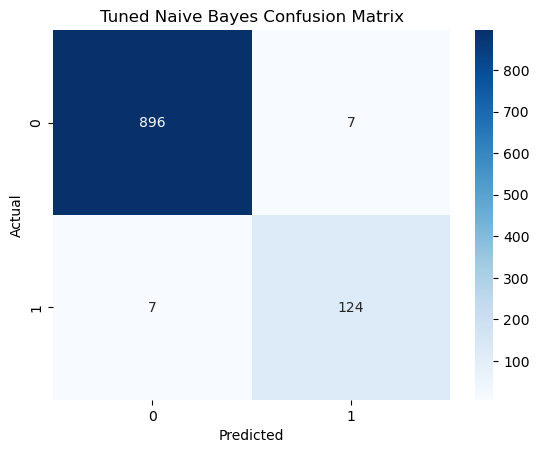

In [29]:
cm = confusion_matrix(y_test, y_pred_best)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.title("Tuned Naive Bayes Confusion Matrix")

plt.show()

In [30]:
comparison = pd.DataFrame({
    "Model": ["Before Tuning", "After Tuning"],

    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, y_pred_best)
    ],

    "F1 Score": [
        f1_score(y_test, y_pred, pos_label="spam"),
        f1_score(y_test, y_pred_best, pos_label="spam")
    ]
})

comparison

,Model,Accuracy,F1 Score
0,Before Tuning,0.981625,0.924901
1,After Tuning,0.986460,0.946565


In [31]:
message = ["Congratulations! You won a free lottery prize."]

message_vector = cv.transform(message)

prediction = best_nb.predict(message_vector)

print("Prediction:", prediction[0])

Prediction: spam


In [35]:
# Save the trained Naive Bayes model
import pickle

pickle.dump(
    best_nb,
    open('model101.pkl', 'wb')
)

# Save the CountVectorizer
pickle.dump(
    cv,
    open('vectorizer101.pkl', 'wb')
)

print("Artifacts Saved Successfully")

Artifacts Saved Successfully
